In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import seaborn as sns

In [13]:
df = pd.read_csv("./data/bmw_cars_market_dataset_synthetic.csv")
df.head()

,car_id,model,year,engine_size,horsepower,fuel_type,transmission,drivetrain,mileage_km,fuel_consumption_l_per_100km,price_usd,co2_emissions_g_km,doors,seats,body_type,color,owner_count,accident_history,service_history,country_sold
0,1,X5,2016,4.0,272,diesel,automatic,AWD,74655,8.9,66756,196.0,5,5,suv,white,2.0,no,partial,Netherlands
1,2,1 Series,2022,2.6,218,petrol,automatic,FWD,23469,8.4,26867,190.0,3,4,hatchback,black,1.0,no,partial,France
2,3,X1,2012,2.2,240,petrol,automatic,FWD,123273,7.8,31313,174.0,5,5,suv,white,3.0,no,full,Netherlands
3,4,X5,2022,3.8,316,diesel,NaN,AWD,33064,9.4,81594,192.0,5,5,suv,blue,1.0,no,NaN,France
4,5,7 Series,2023,3.1,294,petrol,automatic,RWD,23926,NaN,104105,204.0,4,5,sedan,white,1.0,no,full,Spain


In [ ]:
# Find Missing Values
print("Missing Values\n")
print(df.isnull().sum())

sns.heatmap(df.isnull(),cbar=False)
plt.title("Missing Data HeatMap")
plt.show()

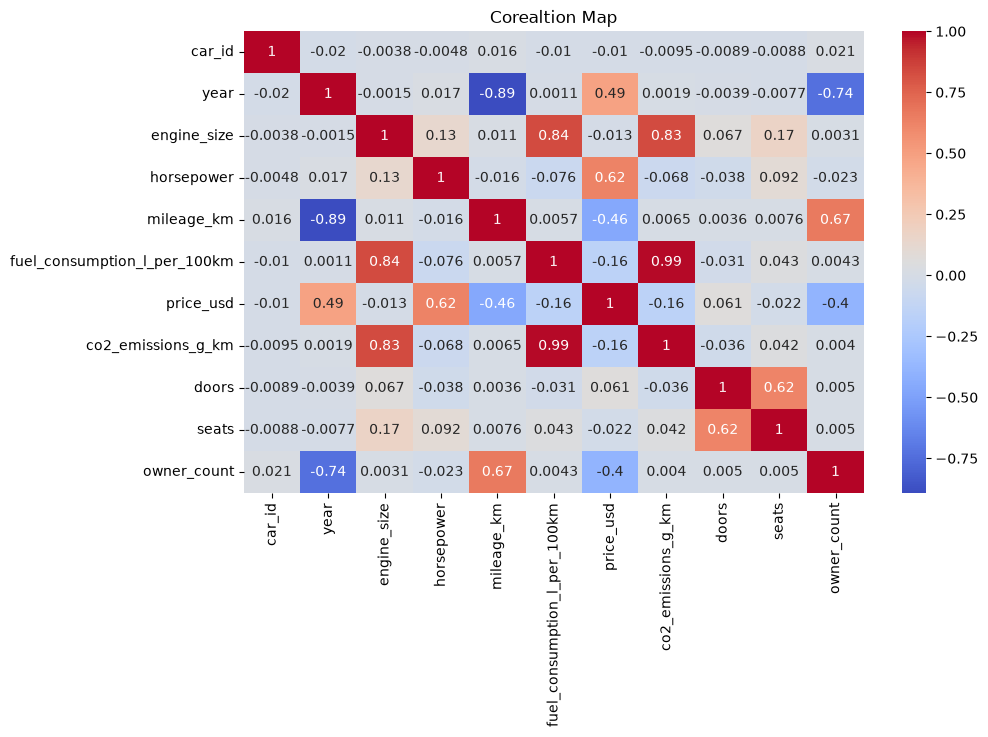

In [21]:
# Basic EDA

#Corelation Heat Map
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.title("Corealtion Map")
plt.show()

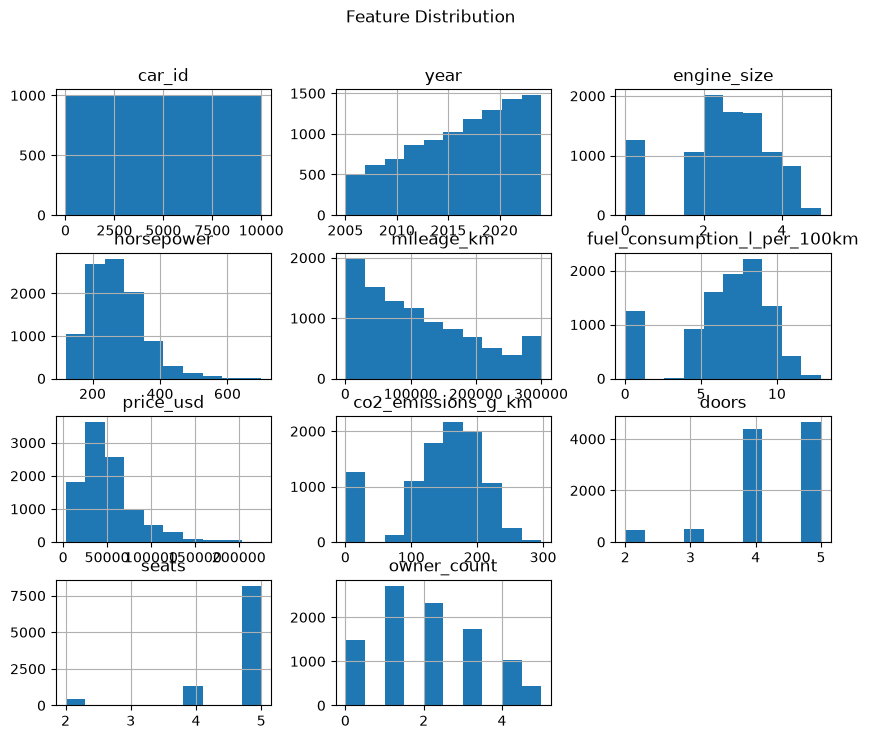

In [22]:
#Distribution of numeric features

df.hist(figsize=(10,8))
plt.suptitle("Feature Distribution")
plt.show()

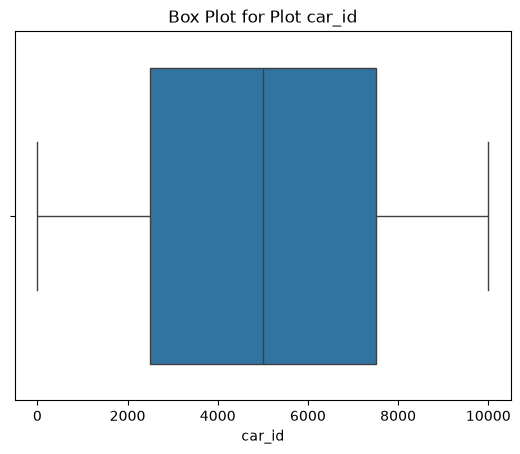

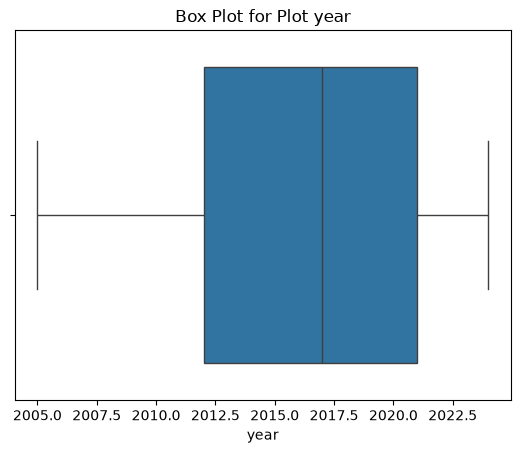

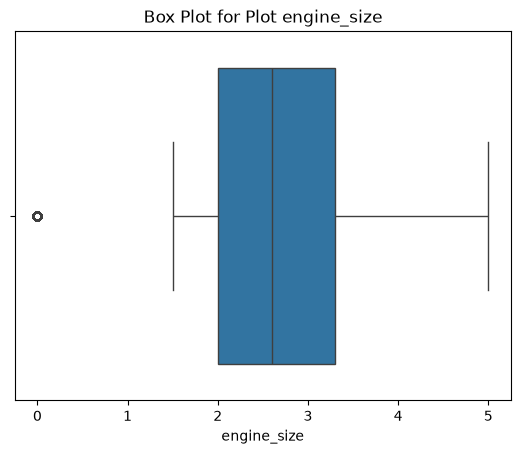

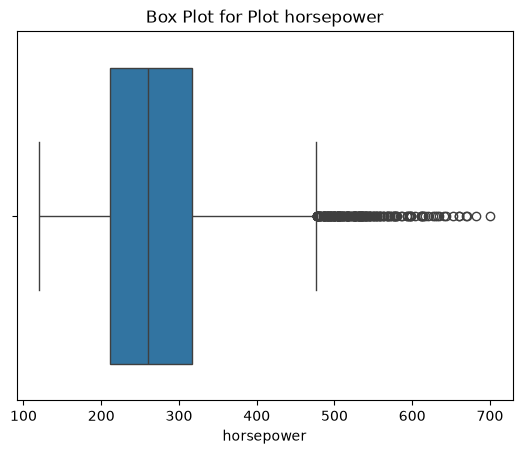

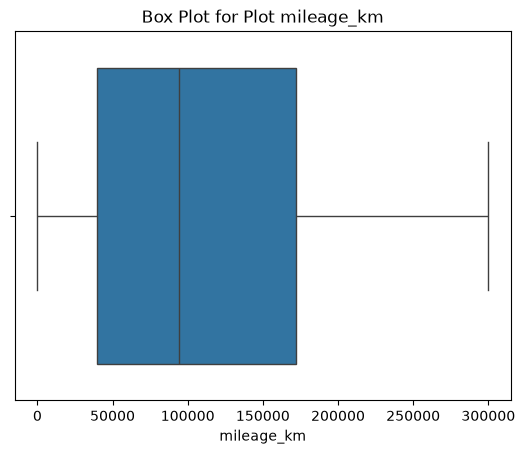

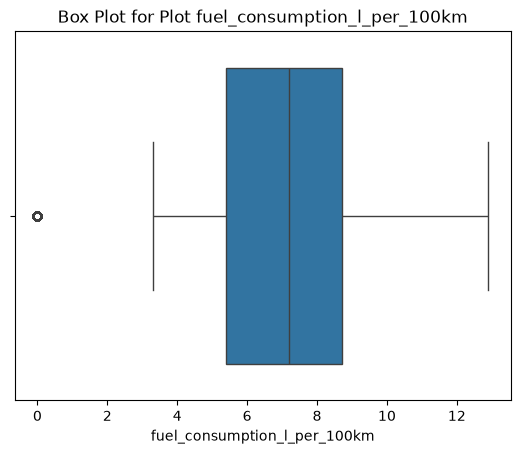

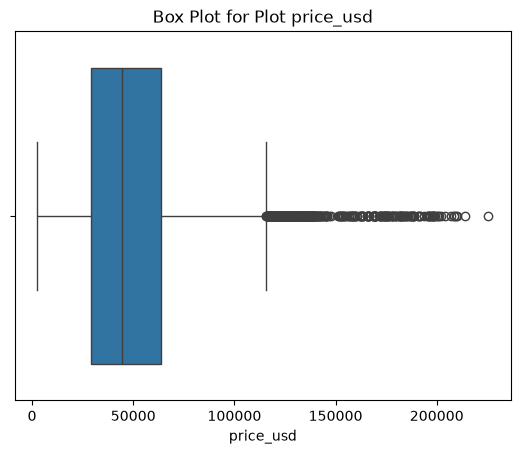

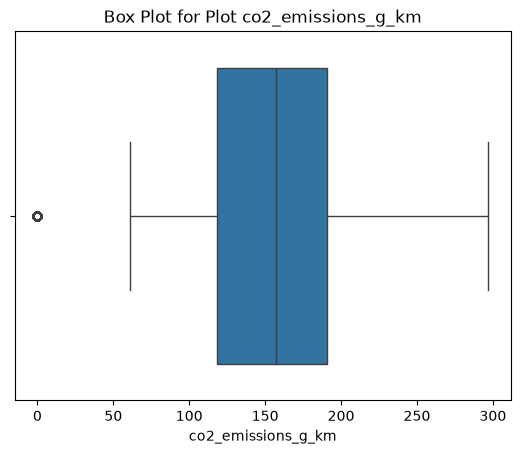

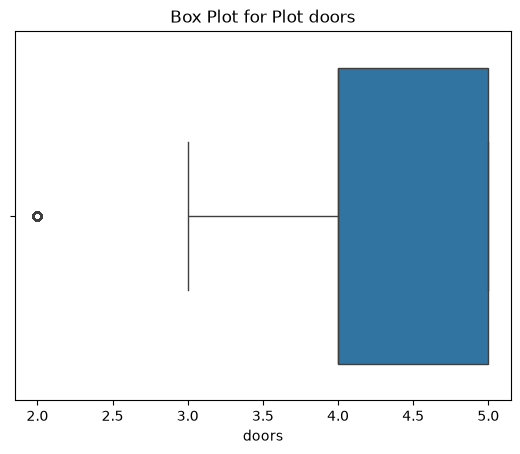

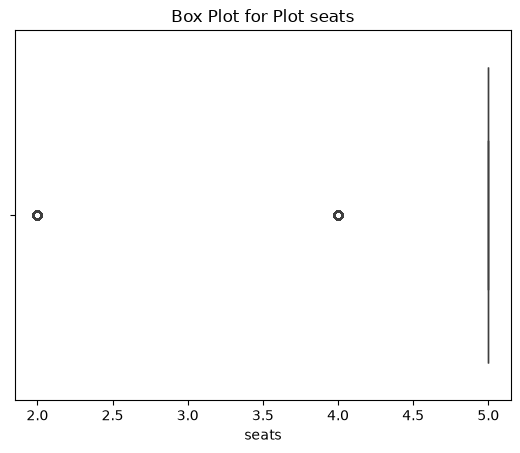

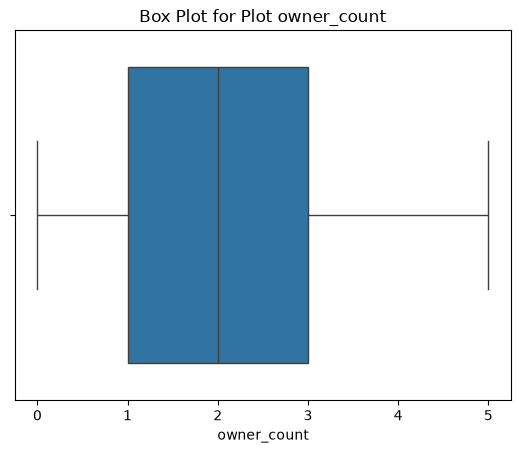

In [23]:
#Box plot for outliers

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot for Plot {col}")
    plt.show()

In [25]:
#Data Cleaning

df = df.drop_duplicates()

cat_cols = df.select_dtypes(include=['object']).columns

#label encoding columns
le = LabelEncoder()

for col in cat_cols:
    df[col] = df[col].astype(str)
    df[col] = le.fit_transform(df[col])

#handle Missing values
imputer = SimpleImputer(strategy="mean")
df[numeric_cols] = imputer.fit_transform(df[numeric_cols])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   car_id                        10000 non-null  float64
 1   model                         10000 non-null  int64  
 2   year                          10000 non-null  float64
 3   engine_size                   10000 non-null  float64
 4   horsepower                    10000 non-null  float64
 5   fuel_type                     10000 non-null  int64  
 6   transmission                  10000 non-null  int64  
 7   drivetrain                    10000 non-null  int64  
 8   mileage_km                    10000 non-null  float64
 9   fuel_consumption_l_per_100km  10000 non-null  float64
 10  price_usd                     10000 non-null  float64
 11  co2_emissions_g_km            10000 non-null  float64
 12  doors                         10000 non-null  float64
 13  seats        

In [ ]:
#Define Features and Target

# Assume last column is target
X = df.iloc[:,:-1] #Add all in X except last columns
y = df.iloc[:,-1] #Add only last column in y

In [27]:
X_train, X_test,y_train,y_test = train_test_split(
    X,y , test_size=0.2,random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

In [28]:
#Define LM Models

models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC()
}

In [ ]:
results = {}

for name,model in models.items():
    print("\n===========")
    print("Model: ",name)
    print("\n===========")

    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    acc= accuracy_score(y_test,y_pred)
    results[name] = acc

    print("Accuracy: ",acc)
    print("confusion_matrix",confusion_matrix(y_test,y_pred))
    print("Classification Report\n",classification_report(y_test,y_pred))


In [30]:
#Model Comparision

results_df = pd.DataFrame(list(results.items()),columns=["Model","Accuracy"])
print("\n Model Performance Comaparision")
print(results_df)


 Model Performance Comaparision
                 Model  Accuracy
0  Logistic Regression    0.1285
1        Random Forest    0.1330
2                  SVM    0.1310


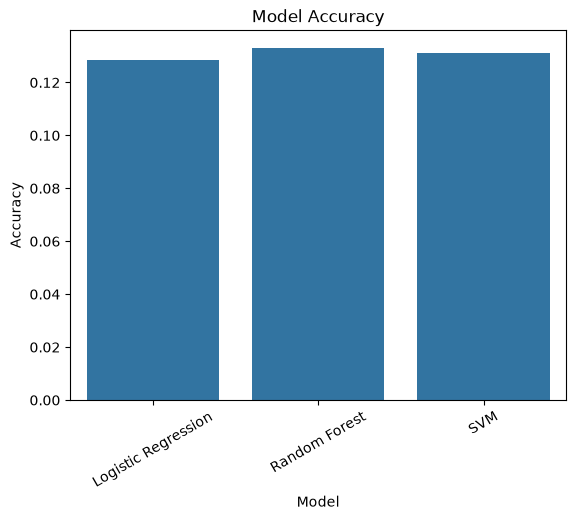

In [31]:
plt.figure()
sns.barplot(x="Model",y="Accuracy",data=results_df)
plt.title("Model Accuracy")
plt.xticks(rotation=30)
plt.show()